# Repressor titration data analysis

## Setup

In [ ]:
try:
    import cdk
    print("CDK already installed, skipping installation and restart.")
except ImportError:
    !pip install nucleus-cdk==0.6.2 -q > /dev/null 2>&1
    print("\nInstallation complete. Restarting runtime to refresh dependencies...")
    import os
    os._exit(0)

CDK already installed, skipping installation and restart.


In [ ]:

import pandas as pd
pd.set_option('display.max_columns', None)
import seaborn as sns
import matplotlib.pyplot as plt

# Import the cdk platereader module
from cdk.instruments import platereader as pr

from cdk import logging
log = logging.setup_logging(logging.ERROR)

## Load Data

In [ ]:
%%writefile drive_utils.py
import os
import re

import gdown


def get_drive_file_id(url):
    """Extract the file ID from a Google Drive share URL."""
    match = re.search(r'/d/([a-zA-Z0-9_-]+)', url)
    if match:
        return match.group(1)
    return None


def download_from_drive(files_info, destination_dir):
    """
    Download files from Google Drive.

    Args:
        files_info (list): List of dicts with 'url' and 'filename'.
        destination_dir (str): Local path to save files.
    Returns:
        dict: Mapping of filenames to local paths.
    """
    os.makedirs(destination_dir, exist_ok=True)

    paths = {}
    for item in files_info:
        url = item['url']
        filename = item['filename']
        dest = os.path.join(destination_dir, filename)
        file_id = get_drive_file_id(url)

        if file_id:
            gdown.download(id=file_id, output=dest, quiet=True)
        else:
            gdown.download(url, output=dest, quiet=True)

        paths[filename] = dest
    return paths

Writing drive_utils.py


In [ ]:
# Set use_drive = True to download data_file and platemap_file from Google Drive instead of
# using local files. Each Drive file must have its permissions set to "Anyone with a link" can "view".
use_drive = True

if use_drive:
    from drive_utils import download_from_drive

    files_to_download = [
        {
            "url": "https://drive.google.com/file/d/1hIHRX1OryR1oOKmk6P2DNQ848UiDwyZb/view?usp=sharing",  # Replace with your data file link.
            "filename": "raw_data.txt",
        },
        {
            "url": "https://drive.google.com/file/d/13M87Y409x-2NTbcbAjeqRYIXsV6QUuFb/view?usp=sharing",  # Replace with your platemap file link.
            "filename": "platemap.csv",
        },
    ]
    downloaded_paths = download_from_drive(files_to_download, destination_dir="data")
    data_file = downloaded_paths["raw_data.txt"]
    platemap_file = downloaded_paths["platemap.csv"]
else:
    data_file = "sample-data/20251111-122213-cytation5-pure-timecourse-gfp-MFG-98-tRNA-QC.txt"
    platemap_file = "sample-data/platemap.csv"

print(f"Data file: {data_file}\nPlatemap file: {platemap_file}")

Data file: data/raw_data.txt
Platemap file: data/platemap.csv


In [ ]:
# Load data
result = pr.load_platereader_data(
    data_file=data_file,
    platemap_file=platemap_file,
    platereader="biotek" # options: "biotek"
)

The output is a list of `PlateReaderResult` objects; if you did more than one read on the plate reader, the results will be in separate objects.

In [ ]:
print(result)

PlateReaderResult with the following 2 blocks:
0: (4307, 41) kinetic read with reads: GFP-G70:485,528 (Fluorescence) (Plate 'Plate 1')
1: (4307, 41) kinetic read with reads: GFP-Gext:485,528 (Fluorescence) (Plate 'Plate 1')


Here there were two reads with different gains but the same excitation/emission spectrum, on one plate. If we want just the `GFP-Gext` read, this corresponds to block index 1, so we can extract that block by indexing:

In [ ]:
desired_index = 1
data = result[desired_index]

You can see the underlying data with `data.view()` (which returns a Pandas DataFrame):

In [ ]:
data.view().head()

,Date,Experiment,Well,Name,Type,Time,Data,Read,Read Name,Reader Type,Reader ID,Plate Type,Plate ID,Start Time,Read Modality,Gain,Excitation Wavelength (nm),Excitation Bandwidth (nm),Excitation Optics,Emission Wavelength (nm),Emission Bandwidth (nm),Emission Optics,Read Geometry,Read Height (mm),Rxn Volume (uL),EsaR Vol (uL),[AHSL] (uM),[Fluorescein] (uM)
0,2026-09-24,EsaO-mNG / [EsaO]2-mNG EsaR titration +/- AHSL,B2,mNG,Sample,0 days 00:01:45,201,"GFP-Gext:485,528",GFP-Gext,Cytation5,1705168,Greiner 384 SV NoBind AutoMap,Plate 1,2026-09-24 15:23:51,Fluorescence,extended,485,20,monochromator,528,20,monochromator,Top,10.5 mm,10,0.0,0,NaN
1,2026-09-24,EsaO-mNG / [EsaO]2-mNG EsaR titration +/- AHSL,B2,mNG,Sample,0 days 00:06:45,226,"GFP-Gext:485,528",GFP-Gext,Cytation5,1705168,Greiner 384 SV NoBind AutoMap,Plate 1,2026-09-24 15:23:51,Fluorescence,extended,485,20,monochromator,528,20,monochromator,Top,10.5 mm,10,0.0,0,NaN
2,2026-09-24,EsaO-mNG / [EsaO]2-mNG EsaR titration +/- AHSL,B2,mNG,Sample,0 days 00:11:45,2840,"GFP-Gext:485,528",GFP-Gext,Cytation5,1705168,Greiner 384 SV NoBind AutoMap,Plate 1,2026-09-24 15:23:51,Fluorescence,extended,485,20,monochromator,528,20,monochromator,Top,10.5 mm,10,0.0,0,NaN
3,2026-09-24,EsaO-mNG / [EsaO]2-mNG EsaR titration +/- AHSL,B2,mNG,Sample,0 days 00:16:45,22158,"GFP-Gext:485,528",GFP-Gext,Cytation5,1705168,Greiner 384 SV NoBind AutoMap,Plate 1,2026-09-24 15:23:51,Fluorescence,extended,485,20,monochromator,528,20,monochromator,Top,10.5 mm,10,0.0,0,NaN
4,2026-09-24,EsaO-mNG / [EsaO]2-mNG EsaR titration +/- AHSL,B2,mNG,Sample,0 days 00:21:45,55139,"GFP-Gext:485,528",GFP-Gext,Cytation5,1705168,Greiner 384 SV NoBind AutoMap,Plate 1,2026-09-24 15:23:51,Fluorescence,extended,485,20,monochromator,528,20,monochromator,Top,10.5 mm,10,0.0,0,NaN


## Plot Raw Curves

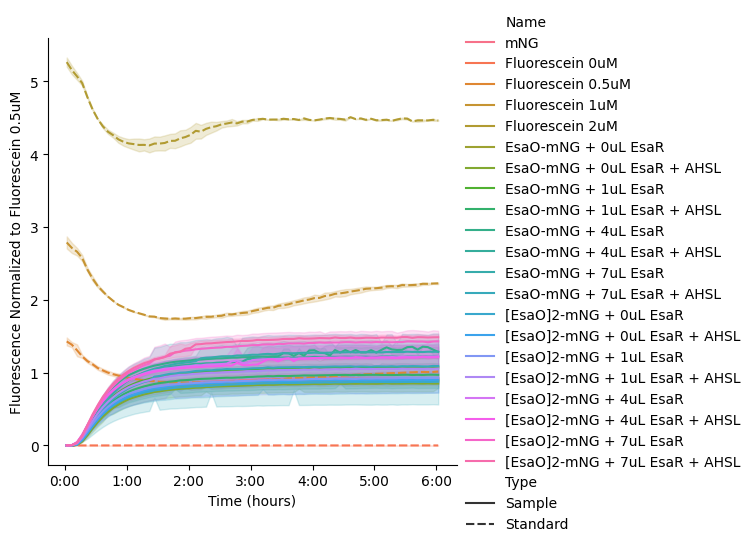

In [ ]:
data.plot(style='Type', hue='Name')

## Plot EsaO-mNG Vs [Esao]2-mNG

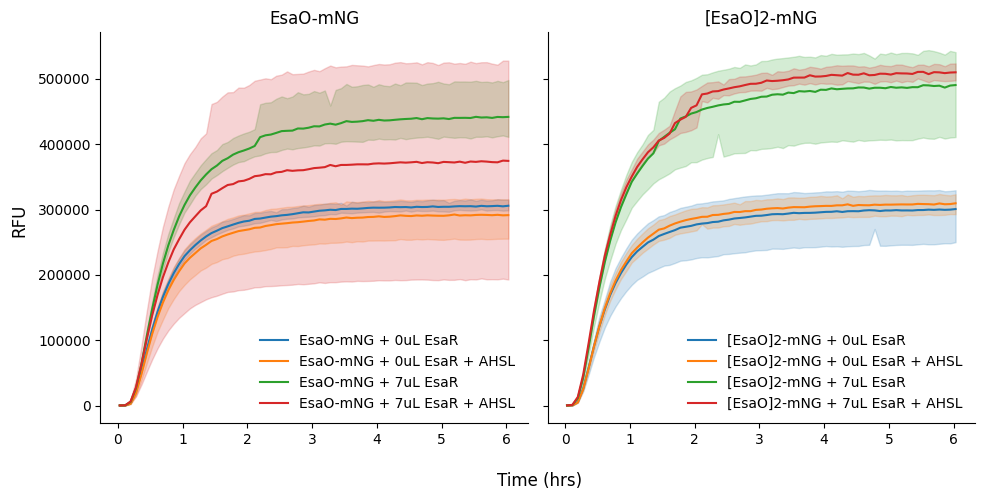

In [ ]:
#| label: fig-20260924-esao

data_EsaO = data.select(name=["EsaO-mNG + 0uL EsaR", "EsaO-mNG + 0uL EsaR + AHSL","EsaO-mNG + 7uL EsaR", "EsaO-mNG + 7uL EsaR + AHSL"])
data_EsaO_2 = data.select(name=["[EsaO]2-mNG + 0uL EsaR", "[EsaO]2-mNG + 0uL EsaR + AHSL","[EsaO]2-mNG + 7uL EsaR", "[EsaO]2-mNG + 7uL EsaR + AHSL"])

df_1 = data_EsaO.data
df_2 = data_EsaO_2.data


# convert timedelta -> float hours
for df in (df_1, df_2):
    df['Time_hrs'] = df['Time'].dt.total_seconds() / 3600

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10,5), sharex=True, sharey=True)

sns.lineplot(data=df_1, x='Time_hrs', y='Data', hue='Name', ax=ax1)
sns.lineplot(data=df_2, x='Time_hrs', y='Data', hue='Name', ax=ax2)

ax1.set(title='EsaO-mNG', xlabel="", ylabel="")
ax2.set(title='[EsaO]2-mNG', xlabel="", ylabel="")
fig.supylabel("RFU", y=0.55)
fig.supxlabel("Time (hrs)", x=0.55)


for ax in (ax1, ax2):
    ax.legend(frameon=False)

sns.despine(fig)
fig.tight_layout()

We can see that the standard (here, HPTS) is stable and can be safely used for normalization.

## Normalize Data
Now, use `data.normalize('<standard name>')` to normalize your data. This will calculate the average over a time window at the end of the experiment (by default, 1 hour), then divide all data by the mean of that window-average across all wells with the same `Name` (defined by your platemap).

In [ ]:
# To check the exact name of your standard
platemap = data.platemap
standards = platemap[platemap['Type']=='Standard']
standards['Name'].unique()

array(['Fluorescein 0uM', 'Fluorescein 0.5uM', 'Fluorescein 1uM',
       'Fluorescein 2uM'], dtype=object)

In [ ]:
data = data.normalize('Fluorescein 0.5uM')

Now replot your curves to see them normalized:

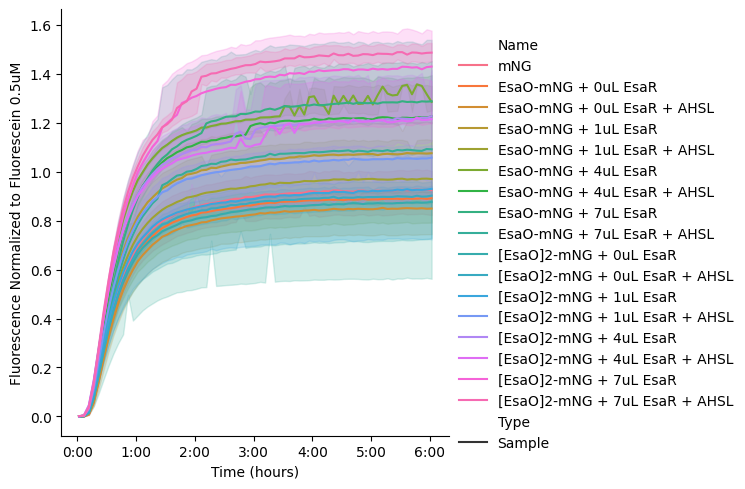

In [ ]:
g = data.plot(style='Type', exclude_types=['Standard'])
# g.savefig('after-normalization.png',dpi=300)

If you want to change the time window over which you calculate the average, you can use the `window` argument:

In [ ]:
# data = data.normalize('10 uM HPTS', window=pd.Timedelta("2.5h"))

## Kinetic Analysis

See the [DevNote](https://devnotes.nucleus.engineering/articles/Newman-20260421) on kinetic analysis for more details.

**Metrics extracted:**

  - **Maximum velocity**: Maximum rate of fluorescence increase (slope at inflection point)
  - **Lag time**: Time to reach the exponential phase
  - **Steady-state**: Final fluorescence level
  - **Time-to-completion**: Time it takes to reach 95% of asymptote
  - **Drift**: Rate of signal decay or increase after steady-state
  - **R²**: Goodness of fit; "Good Fit" is `True` if $R^2 \geq 0.95$

In [ ]:
# Perform kinetic analysis using sigmoid_drift model
kinetics = data.fit_kinetics()

In [ ]:
kinetics.summary

,Well,Name,Max Velocity,Max Velocity Time,Lag Time,Steady State,Completion Time,Completion Threshold,Drift,Fit Function,R^2,Good Fit,Normalized to
0,B2,mNG,0.95,0 days 00:33:24,0 days 00:02:50,0.92,0 days 01:18:23,0.95,0.02,sigmoid_drift,1.00,True,Fluorescein 0.5uM
1,B3,mNG,1.08,0 days 00:34:17,0 days 00:06:06,0.97,0 days 01:15:46,0.95,0.02,sigmoid_drift,0.99,True,Fluorescein 0.5uM
2,B4,mNG,0.81,0 days 00:33:43,0 days 00:02:12,0.81,0 days 01:20:08,0.95,0.02,sigmoid_drift,0.99,True,Fluorescein 0.5uM
3,D2,EsaO-mNG + 0uL EsaR,0.93,0 days 00:33:35,0 days 00:03:06,0.89,0 days 01:18:27,0.95,0.02,sigmoid_drift,1.00,True,Fluorescein 0.5uM
4,D3,EsaO-mNG + 0uL EsaR,0.87,0 days 00:33:57,0 days 00:02:59,0.85,0 days 01:19:33,0.95,0.02,sigmoid_drift,1.00,True,Fluorescein 0.5uM
5,D4,EsaO-mNG + 0uL EsaR,0.87,0 days 00:34:08,0 days 00:02:53,0.86,0 days 01:20:08,0.95,0.02,sigmoid_drift,1.00,True,Fluorescein 0.5uM
6,D6,EsaO-mNG + 0uL EsaR + AHSL,0.70,0 days 00:34:59,0 days 00:02:26,0.73,0 days 01:22:54,0.95,0.02,sigmoid_drift,1.00,True,Fluorescein 0.5uM
7,D7,EsaO-mNG + 0uL EsaR + AHSL,0.94,0 days 00:33:52,0 days 00:03:41,0.90,0 days 01:18:18,0.95,0.02,sigmoid_drift,1.00,True,Fluorescein 0.5uM
8,D8,EsaO-mNG + 0uL EsaR + AHSL,0.89,0 days 00:33:45,0 days 00:03:02,0.86,0 days 01:18:58,0.95,0.02,sigmoid_drift,1.00,True,Fluorescein 0.5uM
9,D10,EsaO-mNG + 1uL EsaR,0.86,0 days 00:32:53,-1 days +23:59:58,0.89,0 days 01:21:21,0.95,0.02,sigmoid_drift,1.00,True,Fluorescein 0.5uM


## Visualize Fits

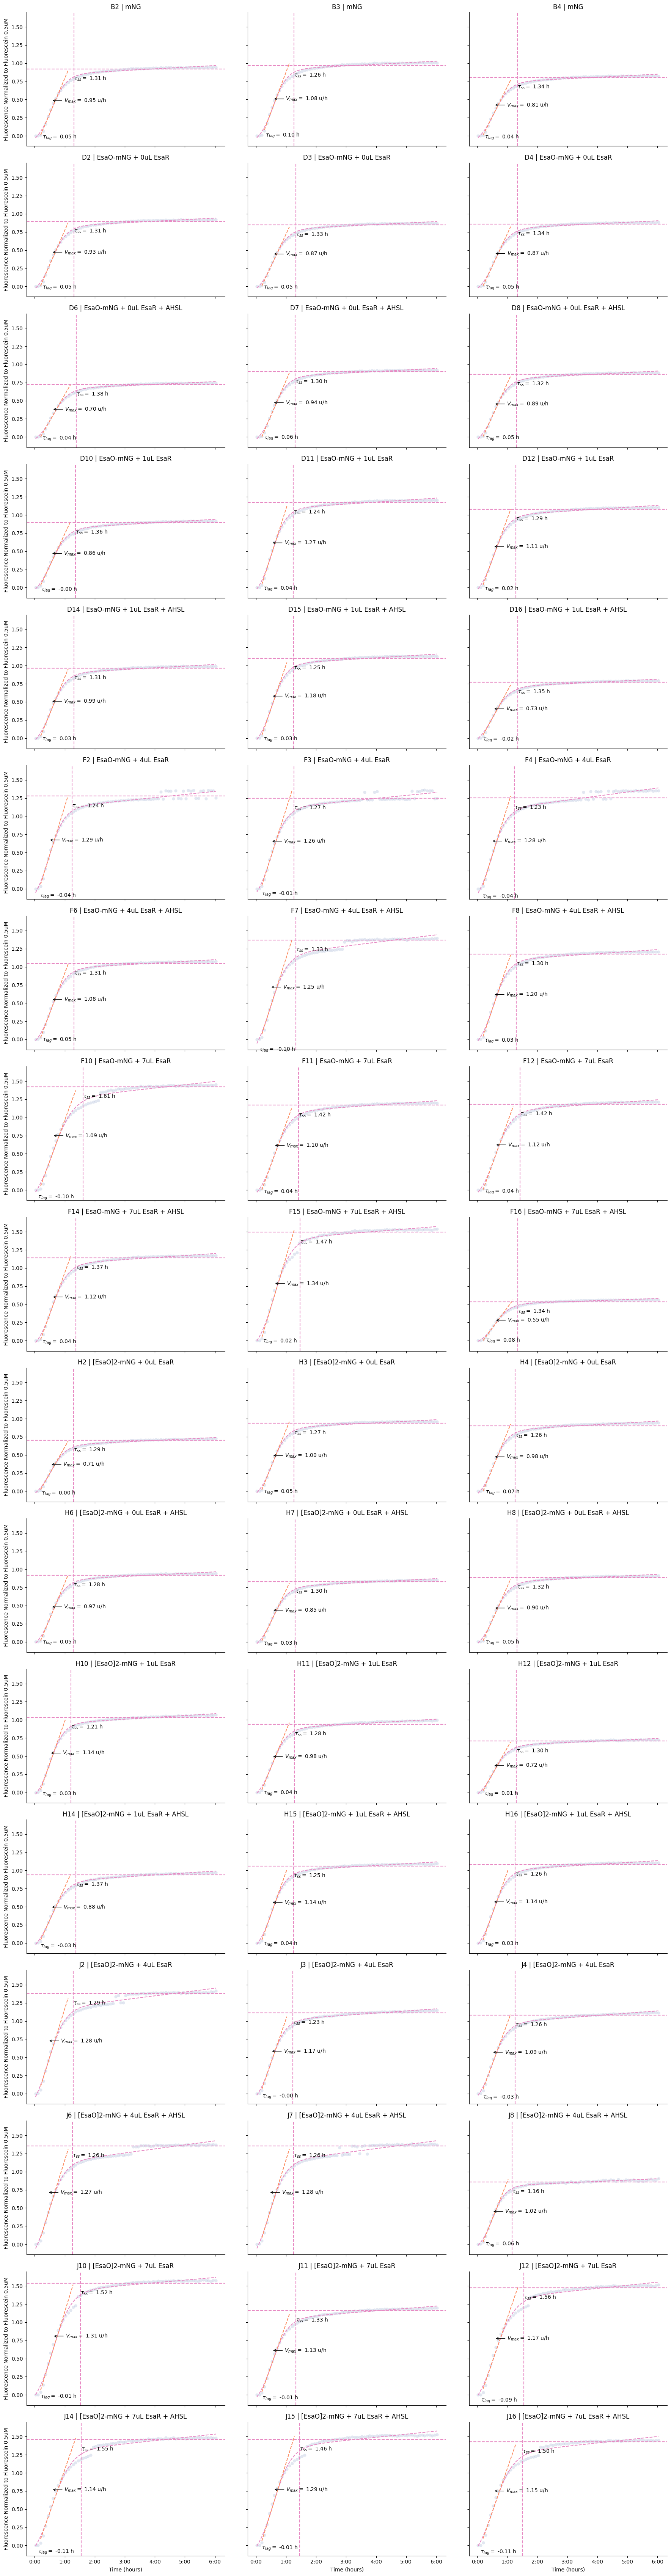

In [ ]:
g = kinetics.plot(col="Well")
# g = kinetics.plot() # call this to visualize across replicates

## Summary Plots

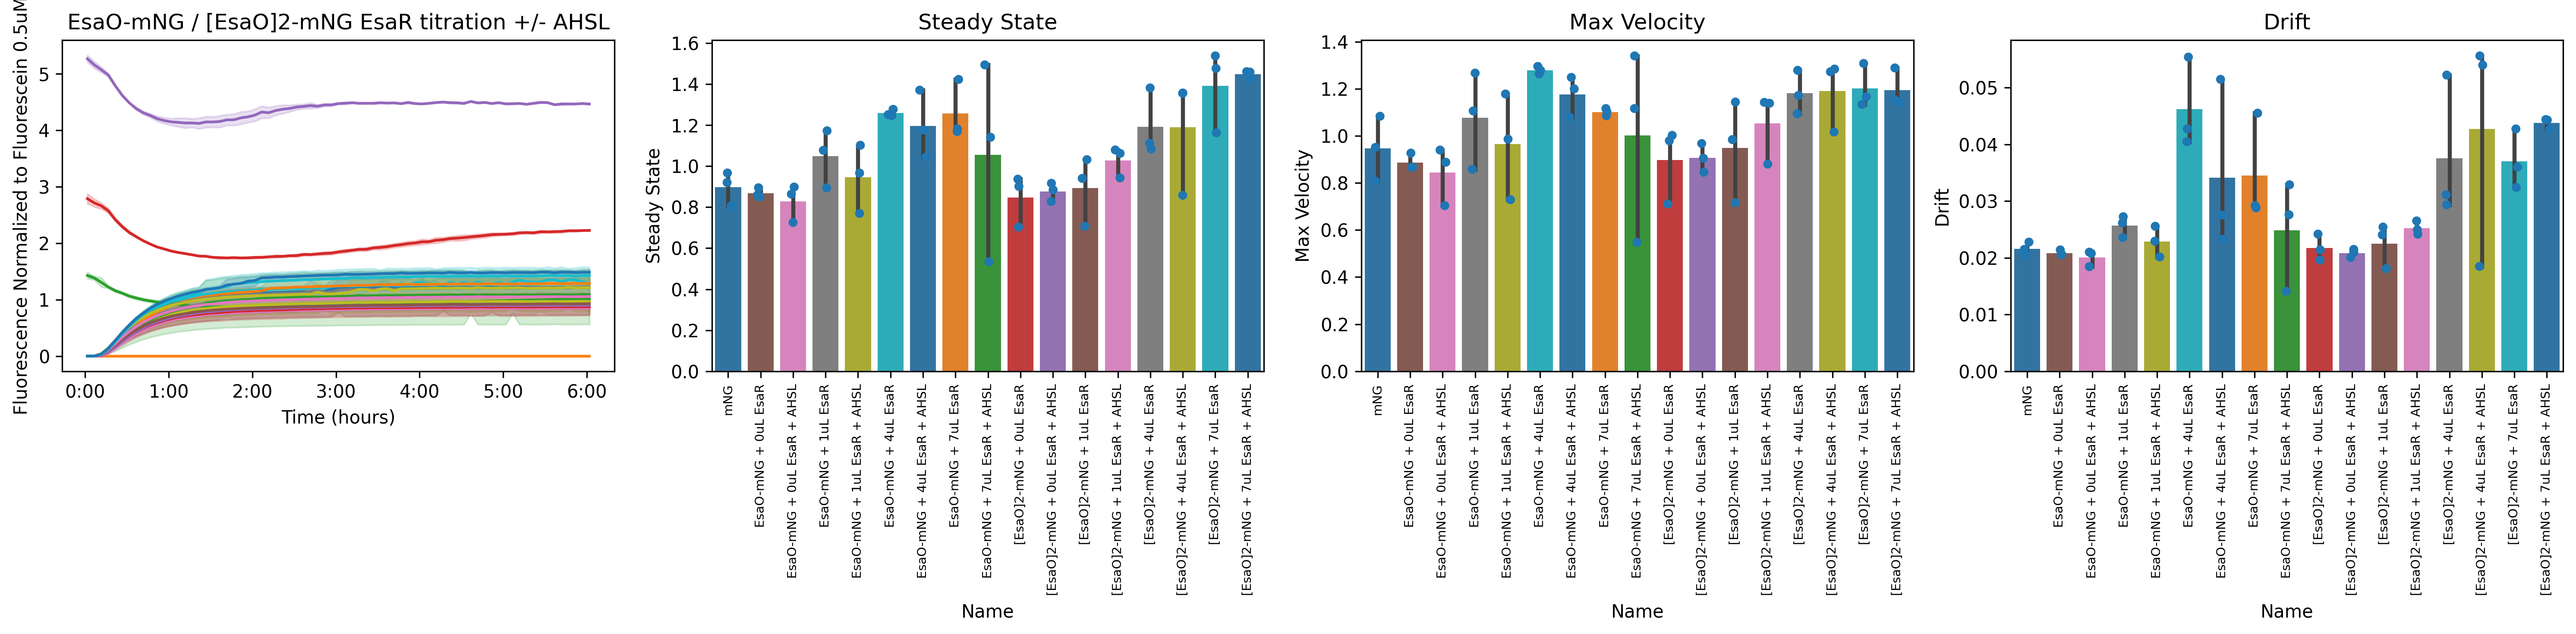

In [ ]:
g = kinetics.plot_summary()

---

## Key Metrics Explained

### 1. **Steady-State Level** (`Steady State, Data`)
- The final fluorescence value reached by the reaction
- Represents the total amount of protein produced
- Higher values indicate greater expression yield

### 2. **Maximum Velocity** (`Velocity, Max`)
- The steepest slope of the fluorescence curve (at the inflection point)
- Units: RFU per second
- Reflects the peak rate of protein synthesis
- Sensitive to enzyme activity, substrate availability, and reaction conditions

### 3. **Lag Time** (`Lag, Time`)
- Time before exponential fluorescence increase begins
- May reflect time for ribosome assembly or initial translation steps
- Shorter lag times suggest faster reaction initiation

### 4. **Drift** (`Fit, drift`)
- Rate of fluorescence change after reaching steady-state
- Positive drift: continued synthesis or aggregation
- Negative drift: photobleaching, protein degradation, or quenching
- Units: RFU per second

### 5. **R² Value** (`Fit, R^2`)
- Goodness of fit (0 to 1, higher is better)
- R² > 0.98 indicates excellent fit
- Poor fits may indicate noisy data, overflow errors, or non-sigmoid kinetics

---

## Tips and Troubleshooting

- **Overflow errors:** Wells with `OVRFLW` or `NaN` values are automatically excluded from fitting
- **Poor fits (low R²):** Inspect raw curves for anomalies (bubbles, evaporation, pipetting errors)
- **Drift:** Sometimes seen in kinetics curves; use `sigmoid_drift` model
- **Multiple replicates:** Always include technical replicates and report error bars
- **Comparing conditions:** Normalize or blank data consistently across all samples

---

## Next Steps

- Export kinetics results: `pr.export_kinetics(kinetics, 'results.csv')`
- Statistical analysis: Use `scipy.stats` or `statsmodels` for ANOVA/t-tests
- Parameter optimization: Vary Mg²⁺, K⁺, or other conditions to maximize Vmax or steady-state
- Mechanistic modeling: Fit ODE models to extract biological rate constants